# Biharmonic equation over the unit circle
Given the following system, defined over a disc $D$:
\begin{equation}
\begin{cases}
-\Delta u - \lambda u = |u|^{p-1}u&\text{ for } p>2, \lambda>0\\
u=0&\text{ on }\partial D
\end{cases}
\end{equation}
If we know that, for a given $p$, some non-trivial solutions satisfy certain topological conditions (eg. a fixed number of sign changes over the domain), then, is it possible to deform an initial guess function $\tilde{u}$, preserving those topological conditions, while minimizing the residuals of the equation ?

To do so, we propose to approximate the solution by $$\hat{u} = P \tilde{u}(F(x)),$$ with $P>0$, and $F(x)$ a diffeomorphism that satisfies $F(\delta d)  \delta d$. In the following, we fix $p = 3$, $\lambda=5$, and $D$ the unit circle.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np

torch.set_default_device(torch.device("mps" if torch.backends.mps.is_available() else "cpu"))
torch.set_default_dtype(torch.float32)
torch.manual_seed(0)

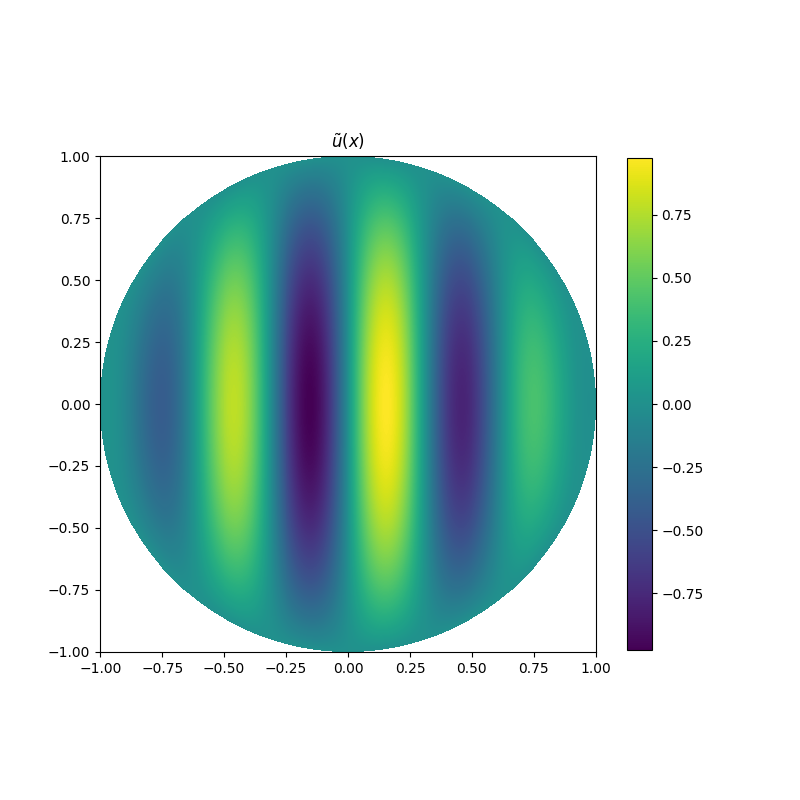

In [141]:
LAMBDA = 5.0
p = 3.0

def u_tilde(x1, x2):
    r2 = x1**2 + x2**2
    if type(x1) == np.ndarray:
        return np.sin(10*x1) * (1 - r2)
    else:
        return torch.sin(10*x1) * (1 - r2)

x = np.linspace(-1, 1, 1000)
X1, X2 = np.meshgrid(x, x)
mask = X1**2 + X2**2 > 1
U = np.ma.array(u_tilde(X1, X2), mask=mask)
m = np.abs(U).max()
fig = plt.figure(figsize=(8, 8))
im = plt.pcolormesh(X1, X2, U, vmin=-m, vmax=m)
plt.gca().set_aspect("equal")
plt.colorbar(im, shrink=0.8)
plt.title(r"$\tilde u(x)$")
plt.show()

In [142]:
def phi(x):        # open disc -> R^2   (hyperbolic radial stretch)
    r = torch.sqrt((x**2).sum(1, keepdim=True) + 1e-12)
    return x * torch.atanh(r.clamp(max=1 - 1e-6)) / r


def phi_inv(z):    # R^2 -> open disc
    r = torch.sqrt((z**2).sum(1, keepdim=True) + 1e-12)
    return z * torch.tanh(r) / r


class AdditiveCoupling(nn.Module):
    def __init__(self, flip, hidden=64, tmax=2.0):
        super().__init__()
        self.flip, self.tmax = flip, tmax
        self.mlp = nn.Sequential(
            nn.Linear(1, hidden), nn.Tanh(),
            nn.Linear(hidden, hidden), nn.Tanh(),
            nn.Linear(hidden, 1),
        )
        nn.init.zeros_(self.mlp[-1].weight)
        nn.init.zeros_(self.mlp[-1].bias)

    def forward(self, z, inverse=False):
        a, b = (z[:, 1:], z[:, :1]) if self.flip else (z[:, :1], z[:, 1:])
        t = self.tmax * torch.tanh(self.mlp(a))
        b = b - t if inverse else b + t
        return torch.cat([b, a], 1) if self.flip else torch.cat([a, b], 1)


class InvertibleNN(nn.Module):
    def __init__(self, n_layers=6, hidden=64, tmax=2.0):
        super().__init__()
        self.layers = nn.ModuleList(
            [AdditiveCoupling(flip=i % 2 == 1, hidden=hidden, tmax=tmax) for i in range(n_layers)]
        )

    def forward(self, x, inverse=False):
        z = phi(x)
        for l in (reversed(self.layers) if inverse else self.layers):
            z = l(z, inverse)
        return phi_inv(z)

In [143]:
def grad(y, x):
    return torch.autograd.grad(y, x, torch.ones_like(y), create_graph=True)[0]

In [144]:
def loss_fn(F, P, x):
    fx = F(x)
    v = u_tilde(fx[:, 0], fx[:, 1])
    u_hat = (nn.Sigmoid()(P)+0.1) * v
    lap = grad(u_hat, x).sum(axis=-1)
    loss = (-lap - LAMBDA * u_hat - P * u_hat.abs() ** (p - 2) * u_hat)**2
    return loss.mean()

def sample_disc(n):
    r = torch.sqrt(torch.rand(n, requires_grad=True))
    th = 2*torch.pi*torch.rand(n, requires_grad=True)
    return torch.stack([r*torch.cos(th), r*torch.sin(th)], 1)

In [145]:
n_epochs = 5000
n_points = 2048

F = InvertibleNN()
P = nn.Parameter(torch.ones(1,))

opt = optim.Adam(list(F.parameters())+[P], lr=1e-3)

for _ in (pbar := tqdm(range(n_epochs))):
    x = sample_disc(n_points)
    loss = loss_fn(F, P, x)
    opt.zero_grad()
    loss.backward()
    opt.step()
    pbar.set_description(f"Loss: {loss.item():.3e}, P: {P.item():.4e}")

  0%|          | 0/5000 [00:00<?, ?it/s]

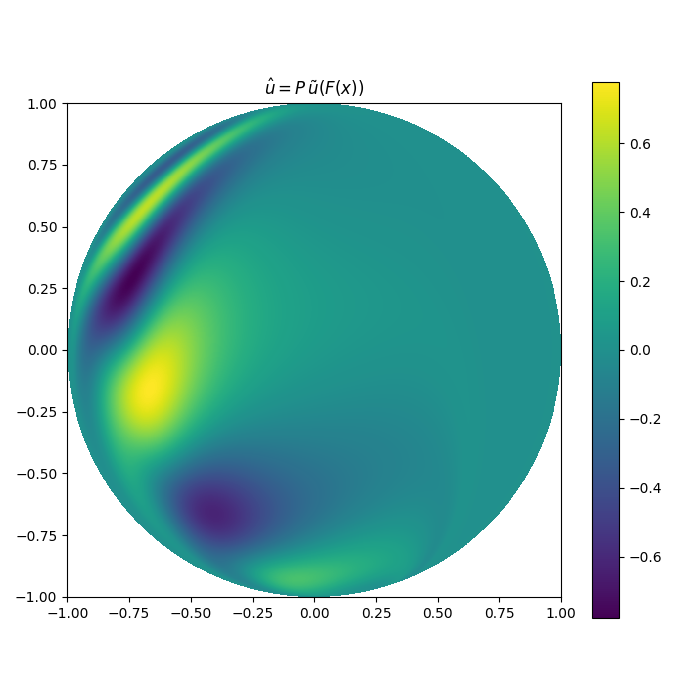

In [146]:
n = 1000
xs = torch.linspace(-1, 1, n)
X1, X2 = torch.meshgrid(xs, xs, indexing="ij")
x = torch.stack([X1, X2], dim=-1).reshape(-1, 2)
with torch.no_grad():
    fx = F(x)
    u = (torch.sigmoid(P) + 0.1) * u_tilde(fx[:, 0], fx[:, 1])

mask = (X1**2 + X2**2 > 1).cpu().numpy()
u_hat = np.ma.array(u.reshape(n, n).cpu().numpy(), mask=mask)

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
m = np.abs(u_hat).max()
im0 = ax.pcolormesh(X1.cpu(), X2.cpu(), u_hat, vmin=-m, vmax=m)
ax.set_title(r"$\hat u = P\,\tilde u(F(x))$")
ax.set_aspect("equal")
plt.colorbar(im0, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()